In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
expiry_df = pd.read_csv(
    "../data/processed/expiry_risk_dataset.csv",
    parse_dates=["snapshot_date"]
)

print("Dataset Shape:", expiry_df.shape)

expiry_df.head()

Dataset Shape: (2500, 10)


,snapshot_date,product_id,batch_id,current_stock,days_to_expiry,avg_daily_demand_30d,avg_daily_demand_90d,expected_demand,stock_demand_ratio,expiry_risk
0,2025-07-01,MED001,MED001_202507_B1,797,59,42.733333,35.022222,2066.311111,0.385712,0
1,2025-07-01,MED001,MED001_202507_B2,495,249,42.733333,35.022222,8720.533333,0.056763,0
2,2025-07-01,MED001,MED001_202507_B3,873,175,42.733333,35.022222,6128.888889,0.142440,0
3,2025-07-01,MED001,MED001_202507_B4,728,58,42.733333,35.022222,2031.288889,0.358393,0
4,2025-07-01,MED001,MED001_202507_B5,184,97,42.733333,35.022222,3397.155556,0.054163,0


In [3]:
expiry_df.info()

print("\nStatistical Summary:")
display(expiry_df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   snapshot_date         2500 non-null   datetime64[us]
 1   product_id            2500 non-null   str           
 2   batch_id              2500 non-null   str           
 3   current_stock         2500 non-null   int64         
 4   days_to_expiry        2500 non-null   int64         
 5   avg_daily_demand_30d  2500 non-null   float64       
 6   avg_daily_demand_90d  2500 non-null   float64       
 7   expected_demand       2500 non-null   float64       
 8   stock_demand_ratio    2500 non-null   float64       
 9   expiry_risk           2500 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(3), str(2)
memory usage: 249.2 KB

Statistical Summary:


,snapshot_date,current_stock,days_to_expiry,avg_daily_demand_30d,avg_daily_demand_90d,expected_demand,stock_demand_ratio,expiry_risk
count,2500,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,2025-08-31 14:24:00,552.532800,203.081200,25.135933,25.124000,5131.937698,0.219013,0.066000
min,2025-07-01 00:00:00,100.000000,30.000000,4.366667,5.133333,165.333333,0.006772,0.000000
25%,2025-08-01 00:00:00,327.000000,122.000000,14.825000,14.727778,2168.933333,0.063111,0.000000
50%,2025-09-01 00:00:00,554.500000,203.500000,25.333333,25.655556,4238.488889,0.118559,0.000000
75%,2025-10-01 00:00:00,783.250000,289.000000,34.900000,34.783333,7462.766667,0.247048,0.000000
max,2025-11-01 00:00:00,1000.000000,365.000000,51.300000,49.966667,17496.466667,4.573440,1.000000
std,NaN,260.172918,96.010009,12.061258,11.669878,3591.920938,0.309930,0.248332


In [4]:
print("Missing Values:")
print(expiry_df.isnull().sum())

print("\nDuplicate Rows:")
print(expiry_df.duplicated().sum())

print("\nDuplicate Batch IDs:")
print(expiry_df["batch_id"].duplicated().sum())

Missing Values:
snapshot_date           0
product_id              0
batch_id                0
current_stock           0
days_to_expiry          0
avg_daily_demand_30d    0
avg_daily_demand_90d    0
expected_demand         0
stock_demand_ratio      0
expiry_risk             0
dtype: int64

Duplicate Rows:
0

Duplicate Batch IDs:
0


expiry_risk
0    2335
1     165
Name: count, dtype: int64


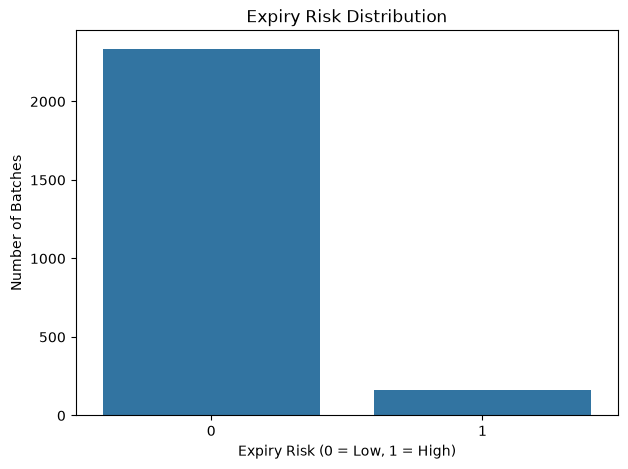

In [5]:
risk_counts = expiry_df["expiry_risk"].value_counts()

print(risk_counts)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=expiry_df,
    x="expiry_risk"
)

plt.title("Expiry Risk Distribution")
plt.xlabel("Expiry Risk (0 = Low, 1 = High)")
plt.ylabel("Number of Batches")

plt.show()

In [6]:
print(
    expiry_df["expiry_risk"]
    .value_counts(normalize=True) * 100
)

expiry_risk
0    93.4
1     6.6
Name: proportion, dtype: float64


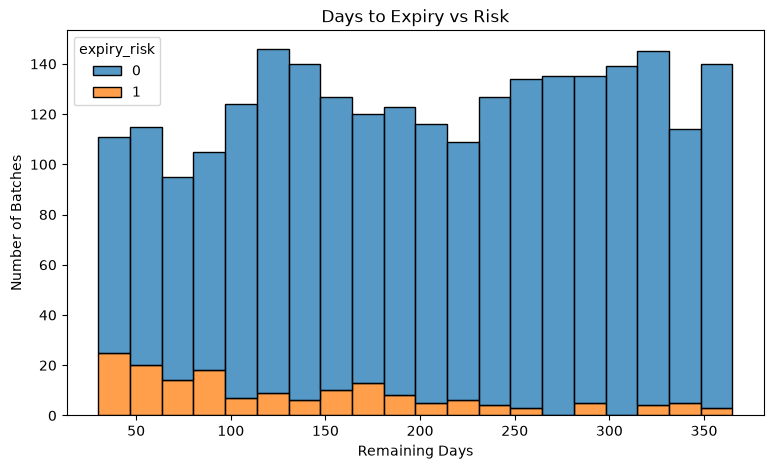

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=expiry_df,
    x="days_to_expiry",
    hue="expiry_risk",
    bins=20,
    multiple="stack"
)

plt.title("Days to Expiry vs Risk")
plt.xlabel("Remaining Days")
plt.ylabel("Number of Batches")

plt.show()

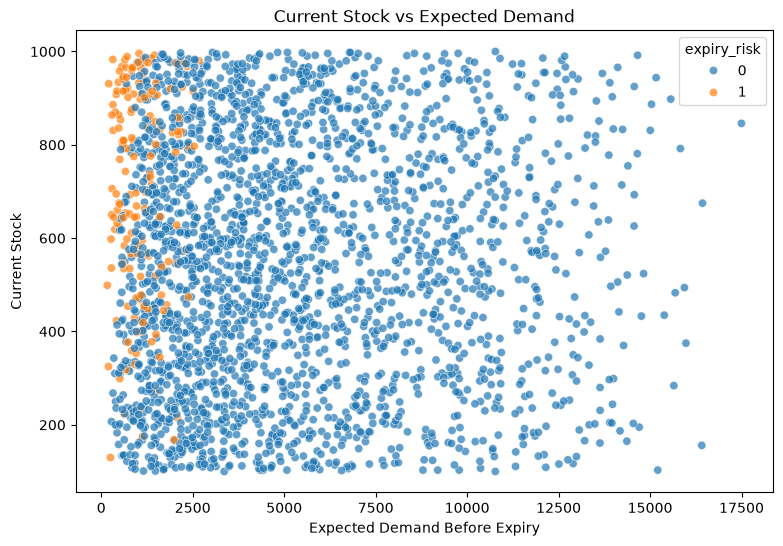

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=expiry_df,
    x="expected_demand",
    y="current_stock",
    hue="expiry_risk",
    alpha=0.7
)

plt.title("Current Stock vs Expected Demand")
plt.xlabel("Expected Demand Before Expiry")
plt.ylabel("Current Stock")

plt.show()

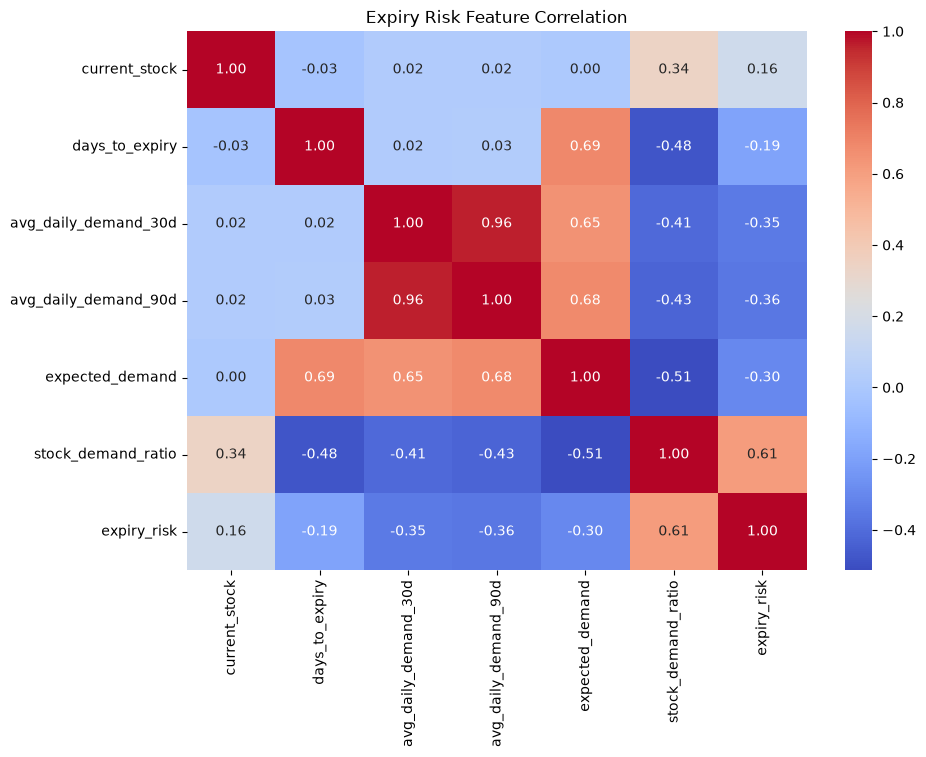

In [9]:
numeric_df = expiry_df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Expiry Risk Feature Correlation")

plt.show()

In [10]:
risk_analysis = expiry_df.groupby(
    "expiry_risk"
).agg({
    "current_stock": "mean",
    "days_to_expiry": "mean",
    "avg_daily_demand_30d": "mean",
    "avg_daily_demand_90d": "mean",
    "expected_demand": "mean",
    "stock_demand_ratio": "mean"
})

display(risk_analysis)

,current_stock,days_to_expiry,avg_daily_demand_30d,avg_daily_demand_90d,expected_demand,stock_demand_ratio
expiry_risk,,,,,,
0,541.434690,207.955889,26.262570,26.243478,5418.892167,0.168404
1,709.587879,134.096970,9.192323,9.281684,1071.097172,0.935209


In [11]:
assert expiry_df["current_stock"].gt(0).all()

assert expiry_df["days_to_expiry"].gt(0).all()

assert expiry_df["expiry_risk"].isin([0, 1]).all()

assert expiry_df["batch_id"].is_unique

assert expiry_df.select_dtypes(
    include=np.number
).notnull().all().all()

print("All basic data quality checks passed!")

All basic data quality checks passed!


In [12]:
Path("../reports").mkdir(
    parents=True,
    exist_ok=True
)

with open("../reports/expiry_eda_summary.txt", "w") as f:

    f.write("PHARMASTOCK AI - EXPIRY RISK EDA\n")
    f.write("================================\n")

    f.write(f"Total records: {len(expiry_df)}\n")

    f.write(
        f"Unique products: "
        f"{expiry_df['product_id'].nunique()}\n"
    )

    f.write(
        f"High risk batches: "
        f"{(expiry_df['expiry_risk'] == 1).sum()}\n"
    )

    f.write(
        f"Low risk batches: "
        f"{(expiry_df['expiry_risk'] == 0).sum()}\n"
    )

    f.write(
        f"Duplicate records: "
        f"{expiry_df.duplicated().sum()}\n"
    )

print("Expiry EDA report saved!")

Expiry EDA report saved!
